# P9. 시퀀싱 데이터의 베이지안: 실제 도구들이 하는 계산을 직접 해 보기

**목표**: P5–P8 에서 배운 우도, 사전, 사후, 격자, 혼합 모형을 시퀀싱 도구들의 실제 계산에 하나씩 대어 봅니다.

| | 무엇을 | 대응하는 도구·논문 |
|---|---|---|
| (a) | read 와 품질 점수로 genotype 사후 구하기, 사전이 왜 필요한지 100 만 자리로 확인 | Li 2011 [1], GATK 사전 [3] |
| (b) | 종양·정상 read 로 "체세포냐 생식세포냐" 가르기 | Mutect2 germline 필터 [4] |
| (c) | VAF 에서 CCF(암세포 중 그 변이를 가진 비율) 사후 구하기, multiplicity 의 역할 | Dentro 2021 [6], Gerstung 2020 [8] |
| (d) | 증폭(gain) 구간의 변이 copy 수로 증폭 시점 추정 | Gerstung 2020 (MutationTimeR) [8] |
| (e) | PURPLE 의 subclonal likelihood(SUBCL) 를 직접 계산 | PURPLE 4.1 [9][10] |
| (f) | (선택) 내 PURPLE 결과에서 CCF 사후와 SUBCL 비교 | — |

**이 노트북이 답하는 질문**: 변이 호출, clonality, 시점 추정 도구의 결과 뒤에는 어떤 베이지안 계산이 있나?

**같이 볼 강의·교재**: BDA3 1–2 장 [11], *Statistical Rethinking* 2023 2강·8강 [12]. 앞 노트북 P5(우도), P6(베이즈 정리), P7(베타–이항), P8(격자·MCMC).

**이 노트북의 데이터**: (a)–(e) 는 모두 실제와 비슷한 숫자로 만든 **가짜 데이터**입니다. (f) 는 환경 변수 `PURPLE_SAMPLE_DIR` 를 정했을 때만 돌고, 저장소에 올리는 사본은 이 절을 건너뛴 채 실행됩니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 뜻 고정 — 사전 하늘, 우도 주황, 사후 파랑, 증거 진회색, 핵심 자주
import logging, math, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from scipy import stats, special

warnings.filterwarnings("ignore", category=RuntimeWarning)
COL = dict(prior="#56B4E9", likelihood="#E69F00", posterior="#0072B2", evidence="#374151",
           highlight="#CC79A7", ink="#222222", muted="#6B7280", grid="#E5E7EB", none="#D1D5DB",
           ok="#009E73", alt="#D55E00", ref="#9CA3AF", shade="#F3F4F6")

def apply_theme():
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white"})

def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목'"""
    ax.set_title(f"{letter}   {title}")

def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)

def callout(ax, x, y, text, **kw):
    """핵심 메시지 한 줄: 자주색 굵은 글씨, 흰 바탕"""
    kw.setdefault("fontsize", 10); kw.setdefault("color", COL["highlight"]); kw.setdefault("fontweight", "semibold")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, **kw)

def ygrid(ax):
    ax.yaxis.grid(True); ax.set_axisbelow(True)

def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.03):
    """수식을 조각으로 그린다. parts = [(mathtext, 색 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 아래 그림의 같은 색과 짝을 이룬다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); x = 0.0; items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lw = 0.0
        if label:                                          # 이름표가 조각보다 넓으면 그만큼 자리를 더 준다
            lt = ax.text(0, 0, label, fontsize=9.5, fontweight="semibold", transform=ax.transAxes)
            lw = lt.get_window_extent(renderer=r).transformed(inv).width; lt.remove()
        slot = max(bb.width, lw)
        items.append((t, bb, color, label, x + (slot - bb.width) / 2)); x += slot + gap
    shift = (1 - (x - gap)) / 2                            # 가운데 정렬
    for t, bb, color, label, x0 in items:
        t.set_x(x0 + shift)
        if color:
            ax.add_patch(FancyBboxPatch((x0 + shift - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if label:
            ax.text(x0 + shift + bb.width / 2, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                    color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)

def show_formula(parts, title=None, height=1.5, width=11):
    """수식 조각 그림만 한 장으로"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11.5, fontweight="semibold", transform=ax.transAxes)
    plt.show()

def concept_map(nodes, edges, title="Concept map", size=(11, 3.2)):
    """nodes = {key: (x, y, text, color)}, edges = [(from, to, label)] — 상자와 화살표"""
    fig, ax = plt.subplots(figsize=size)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_axis_off()
    boxes = {}
    for k, (x, y, text, c) in nodes.items():
        t = ax.text(x, y, text, ha="center", va="center", fontsize=10, color=COL["ink"], zorder=3,
                    bbox=dict(boxstyle="round,pad=0.45", facecolor=c if c != "white" else "white",
                              alpha=0.25 if c != "white" else 1, edgecolor=c if c != "white" else COL["muted"],
                              linewidth=1.0))
        boxes[k] = t
    fig.canvas.draw(); r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted()
    ext = {}
    for k, t in boxes.items():                             # 상자 크기(축 좌표)
        bb = t.get_bbox_patch().get_window_extent(r).transformed(inv)
        ext[k] = (bb.x0, bb.y0, bb.x1, bb.y1)

    def edge_point(k, dx, dy):
        x0, y0, x1, y1 = ext[k]; cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        hw, hh = (x1 - x0) / 2 + 0.008, (y1 - y0) / 2 + 0.02
        s = min(hw / abs(dx) if dx else 1e9, hh / abs(dy) if dy else 1e9)
        return cx + dx * s, cy + dy * s

    for a, b, lab in edges:
        (ax0, ay0, ax1, ay1), (bx0, by0, bx1, by1) = ext[a], ext[b]
        ca, cb = ((ax0 + ax1) / 2, (ay0 + ay1) / 2), ((bx0 + bx1) / 2, (by0 + by1) / 2)
        dx, dy = cb[0] - ca[0], cb[1] - ca[1]
        p0 = edge_point(a, dx, dy); p1 = edge_point(b, -dx, -dy)
        ax.annotate("", xy=p1, xytext=p0, xycoords="axes fraction", textcoords="axes fraction",
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.0, mutation_scale=12,
                                    shrinkA=0, shrinkB=0), zorder=2)
        if lab:
            note(ax, (p0[0] + p1[0]) / 2, (p0[1] + p1[1]) / 2 + 0.05, lab, ha="center", fontsize=8.5,
                 transform=ax.transAxes)
    ax.set_title(title)
    plt.show()

def phred_to_e(q):
    """Phred 점수 → 오류 확률: Q = -10 log10(e) [Cock 2010]"""
    return 10 ** (-np.asarray(q, float) / 10)

apply_theme()

In [2]:
# 이 노트북의 그림 함수와 계산 도구
GENO = ["0/0", "0/1", "1/1"]
PRIOR_G = np.array([1 - 1.5e-3, 1e-3, 0.5e-3])        # P6 과 같은 장난감 사전(GATK 주석의 1 - Σ het/i, N = 1)

def p_alt_read(g_idx, e):
    """두 염기 모형(Li 2011): genotype 의 참조 allele 수 g = 2, 1, 0 → 변이로 보일 확률"""
    g_ref = np.array([2, 1, 0])[g_idx]
    return ((2 - g_ref) * (1 - e) + g_ref * e) / 2

def geno_loglik_counts(n30, a30, n10, a10):
    """품질 Q30·Q10 두 종류의 read 수만으로 세 genotype 의 로그 우도 (Li 2011 식 (2) 를 개수로 묶은 것)"""
    out = np.zeros((len(n30), 3))
    for j in range(3):
        for n, a, e in [(n30, a30, 1e-3), (n10, a10, 0.1)]:
            pa = p_alt_read(j, e)
            out[:, j] += a * np.log(pa) + (n - a) * np.log(1 - pa)
    return out

def softmax_rows(x):
    x = x - x.max(1, keepdims=True); p = np.exp(x); return p / p.sum(1, keepdims=True)

def draw_calling(conf, calib):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.3, "width_ratios": [1, 1.1]})
    ax = axs[0]
    labels = ["false positives\n(called 0/1 or 1/1,\ntruly 0/0)", "false negatives\n(called 0/0,\ntruly variant)"]
    x = np.arange(2)
    ax.bar(x - 0.19, [conf["mle"]["fp"], conf["mle"]["fn"]], width=0.36, color=COL["likelihood"], label="likelihood only (MLE)")
    ax.bar(x + 0.19, [conf["post"]["fp"], conf["post"]["fn"]], width=0.36, color=COL["posterior"], label="posterior (with prior)")
    for xx, k in zip(x, ["fp", "fn"]):
        ax.text(xx - 0.19, conf["mle"][k], f"{conf['mle'][k]:,}", ha="center", va="bottom", fontsize=9.5)
        ax.text(xx + 0.19, conf["post"][k], f"{conf['post'][k]:,}", ha="center", va="bottom", fontsize=9.5)
    ax.set_xticks(x, labels); ax.set_ylabel("sites"); ygrid(ax); ax.legend(loc="upper right")
    panel(ax, "A", f"Errors over {conf['n']:,} simulated sites")
    ax = axs[1]
    ax.plot([0, 1], [0, 1], color=COL["muted"], lw=0.8, ls=":")
    ax.plot(calib["mid"], calib["frac"], "o-", color=COL["posterior"], lw=2, ms=6)
    last = len(calib["mid"]) - 1
    for k_, (m, f_, n) in enumerate(zip(calib["mid"], calib["frac"], calib["n"])):
        if k_ == last:                                   # 마지막 점은 왼쪽 위, 나머지는 오른쪽 아래(선은 오른쪽 위로 감)
            ax.text(m - 0.02, f_ + 0.035, f"n={n:,}", ha="right", va="bottom", fontsize=8.5, color=COL["muted"])
        else:
            ax.text(m + 0.025, f_ - 0.045, f"n={n:,}", ha="left", va="top", fontsize=8.5, color=COL["muted"])
    ax.set_xlim(0, 1.15); ax.set_ylim(0, 1.08)
    ax.set_xlabel("posterior P(variant) reported for a site"); ax.set_ylabel("share truly variant"); ygrid(ax)
    panel(ax, "B", "Calibration: a posterior of 0.9 should be right 90% of the time")
    callout(ax, 0.03, 0.95, "points on the dotted line\n= honest probabilities", va="top", fontsize=9.5)
    plt.show()

def log_binom(a, d, p):
    return stats.binom.logpmf(a, d, np.clip(p, 1e-12, 1 - 1e-12))

def germline_filter(a_t, d_t, a_n, d_n, f_pop, pi=1e-6, mu=0.5, eps=1e-3, normal=True):
    """Mutect2 기술 문서 Germline Filter 절의 세 가능성을 이항 우도로 옮긴 장난감.
    f_pop = 집단 allele 빈도(문서의 f), mu = 구간의 minor allele 비율(문서의 m), pi = 체세포 사전.
    우도는 모두 '그 allele 이 없고 오류만 있다'(eps)에 대한 비로 둔다(문서의 약속). 반환: 로그 비정규 확률 3 개."""
    f, m = f_pop, mu
    base_t = log_binom(a_t, d_t, eps)
    lt = lambda af: log_binom(a_t, d_t, af) - base_t
    lt_som = -np.log(d_t + 1) - base_t                  # 체세포: AF 를 0~1 평평 사전으로 적분하면 1/(d+1)
    if normal:
        base_n = log_binom(a_n, d_n, eps)
        ln_het = log_binom(a_n, d_n, 0.5) - base_n; ln_hom = log_binom(a_n, d_n, 1 - eps) - base_n
    else:
        ln_het = ln_hom = 0.0                            # 짝 정상 시료 없음: l_n = 1
    het = np.log(f * (1 - f)) + ln_het + np.log(1 - pi) + np.logaddexp(lt(m), lt(1 - m))
    hom = 2 * np.log(f) + ln_hom + lt(1 - eps) + np.log(1 - pi)
    som = 2 * np.log1p(-f) + lt_som + np.log(pi)
    return np.array([het, hom, som])

def to_prob(logw):
    logw = np.asarray(logw); m = logw.max(0); w = np.exp(logw - m); return w / w.sum(0)

def draw_germline(scen):
    fig, ax = plt.subplots(figsize=(11, 3.6))
    names = ["germline het", "germline hom alt", "somatic"]
    cols = [COL["muted"], COL["none"], COL["alt"]]          # 판정 결과: germline 은 회색 둘, 체세포는 변이 빨강
    txt = ["white", COL["ink"], "white"]
    for i, (lab, pr) in enumerate(scen):
        left = 0
        for j in range(3):
            ax.barh(i, pr[j], left=left, color=cols[j], height=0.55)
            if pr[j] > 0.08:
                ax.text(left + pr[j] / 2, i, f"{pr[j]:.2f}", ha="center", va="center", color=txt[j], fontsize=9.5, fontweight="bold")
            left += pr[j]
    ax.set_yticks(range(len(scen)), [s[0] for s in scen]); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_xlabel("posterior probability")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=c, label=n) for n, c in zip(names, cols)], loc="upper center",
              bbox_to_anchor=(0.5, -0.22), ncol=3)
    panel(ax, "", "Somatic or germline? Same tumour reads, different normal and population evidence")
    plt.show()

def draw_tumour_only(vaf_grid, af_grid, p_som, depth):
    fig, ax = plt.subplots(figsize=(9, 4.2))
    im = ax.pcolormesh(vaf_grid, af_grid, p_som, cmap="Blues", vmin=0, vmax=1, shading="auto")
    cs = ax.contour(vaf_grid, af_grid, p_som, levels=[0.5], colors=[COL["highlight"]], linewidths=1.6)
    ax.set_yscale("log"); ax.set_xlabel(f"tumour VAF (depth {depth}, no matched normal)")
    ax.set_ylabel("population allele frequency f_pop\n(e.g. from gnomAD)")
    cb = fig.colorbar(im, ax=ax, pad=0.02); cb.set_label("P(somatic)")
    panel(ax, "", "Tumour-only calling: VAF and the population prior decide together")
    callout(ax, 0.42, 3e-2, "purple line: P(somatic) = 0.5", fontsize=9.5)
    plt.show()

CCF_GRID = np.linspace(0.005, 1.0, 400)

def ccf_post(alt, dp, purity, cn, m, grid=CCF_GRID):
    """Dentro 2021 / Gerstung 2020 의 기대 VAF 식: VAF = m·CCF·p / (p·CN + 2(1-p)), 이항 우도, 평평한 사전"""
    vaf = m * grid * purity / (purity * cn + 2 * (1 - purity))
    ll = log_binom(alt, dp, vaf)
    post = np.exp(ll - ll.max()); return post / post.sum()

def draw_ccf_cases(cases):
    fig, axs = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=False, gridspec_kw={"wspace": 0.25})
    for ax, (title, items) in zip(axs, cases):
        for i_, item in enumerate(items):
            lab, post, c = item[:3]; ls = item[3] if len(item) > 3 else "-"
            ax.fill_between(CCF_GRID, post / post.max(), color=c, alpha=0.18 if ls == "-" else 0.08, lw=0)
            ax.plot(CCF_GRID, post / post.max(), color=c, lw=2, ls=ls)
            ax.text(0.03, 0.95 - 0.1 * i_, ("- - " if ls != "-" else "— ") + lab, color=c, ha="left", va="top", fontsize=9.5,
                    fontweight="semibold", transform=ax.transAxes)
        ax.axvspan(0.9, 1.0, color=COL["shade"], lw=0, zorder=0)
        ax.set_xlabel("CCF"); ax.set_yticks([]); ax.spines["left"].set_visible(False); ax.set_ylim(0, 1.28)
        panel(ax, "ABC"[[c[0] for c in cases].index(title)], title)
    note(axs[0], 0.99, 1.2, "grey band: CCF ≥ 0.9", ha="right", va="center", color=COL["ink"], fontsize=8.5)   # 곡선 위 빈 자리
    plt.show()

def draw_timing_schematic(ax):
    ax.set_xlim(0, 1); ax.set_ylim(-0.9, 3.6); ax.set_axis_off()
    T = 0.4
    ax.plot([0, 1], [0.5, 0.5], color=COL["ref"], lw=5, solid_capstyle="round")
    ax.plot([0, T], [2.0, 2.0], color=COL["posterior"], lw=5, solid_capstyle="round")
    for yy in (1.6, 2.4):
        ax.plot([T, 1], [yy, yy], color=COL["posterior"], lw=5, solid_capstyle="round")
    ax.plot([T, T], [1.6, 2.4], color=COL["posterior"], lw=1.2)
    ax.vlines(T, 1.2, 3.1, color=COL["highlight"], lw=1.2, ls=(0, (3, 2)))     # 아래 설명 글과 겹치지 않게 염색체 쪽만
    note(ax, T + 0.01, 3.2, "gain (time T)", color=COL["highlight"], fontweight="semibold")
    for xx in (0.12, 0.28):                                # 증폭 전, 증폭될 copy 에 생긴 변이
        ax.plot([xx], [2.0], "*", color=COL["alt"], ms=12)
    for yy in (1.6, 2.4):                                  # 증폭 뒤 두 copy 모두가 그 변이를 물려받음
        ax.plot([T + 0.06, T + 0.12], [yy, yy], "*", color=COL["alt"], ms=8, alpha=0.75)
    for xx in (0.6, 0.85):                                 # 증폭 뒤 한 copy 에만 생긴 변이
        ax.plot([xx], [2.4], "*", color=COL["ok"], ms=12)
    ax.plot([0.2], [0.5], "*", color=COL["ok"], ms=12); ax.plot([0.7], [0.5], "*", color=COL["ok"], ms=12)
    note(ax, 0.0, 2.95, "gained homolog", color=COL["posterior"], fontweight="semibold")
    note(ax, 0.0, 0.95, "other homolog", color=COL["muted"], fontweight="semibold")
    note(ax, 0.0, -0.05, "red ★ arose before the gain on the gained copy:\ncopied with it → 2 copies (m = 2).  green ★ → 1 copy (m = 1)",
         color=COL["ink"], fontsize=8.5, va="top")
    panel(ax, "A", "Multiplicity dates a 2+1 gain")

def draw_timing(alt, dp, v1, v2, Tgrid, postT, T_true, T_hard):
    fig = plt.figure(figsize=(12.5, 4.2))
    gs = fig.add_gridspec(1, 3, width_ratios=[1.15, 1, 1], wspace=0.3)
    draw_timing_schematic(fig.add_subplot(gs[0]))
    ax = fig.add_subplot(gs[1])
    ax.hist(alt / dp, bins=40, color=COL["none"])
    for v, lab, c in [(v1, "m = 1", COL["ok"]), (v2, "m = 2", COL["alt"])]:
        ax.axvline(v, color=c, lw=1.6); note(ax, v + 0.01, ax.get_ylim()[1] * 0.9, f"{lab}\nVAF {v:.2f}", color=c, fontweight="semibold")
    ax.set_xlabel("VAF of mutations in the gained region"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    panel(ax, "B", "Two VAF peaks")
    ax = fig.add_subplot(gs[2])
    ax.fill_between(Tgrid, postT, color=COL["posterior"], alpha=0.25, lw=0); ax.plot(Tgrid, postT, color=COL["posterior"], lw=2)
    ax.axvline(T_true, color=COL["highlight"], lw=1.4)
    note(ax, T_true - 0.03, postT.max() * 0.95, "truth", color=COL["highlight"], ha="right")    # 봉우리 왼쪽 빈 자리
    ax.axvline(T_hard, color=COL["ink"], lw=1, ls=":"); note(ax, T_hard + 0.06, postT.max() * 0.45, "dotted: hard counts", color=COL["ink"])
    ax.set_xlabel("molecular time of the gain T"); ax.set_yticks([]); ax.spines["left"].set_visible(False)
    panel(ax, "C", "Posterior of T")
    plt.show()

def draw_subcl(vcn, edges, hist_c, hist_s, subcl_bucket, resp, subcl_var):
    fig, axs = plt.subplots(1, 3, figsize=(12.8, 3.9), gridspec_kw={"wspace": 0.3})
    ax = axs[0]
    ax.hist(vcn, bins=edges, color=COL["none"])
    ctr = (edges[:-1] + edges[1:]) / 2
    ax.step(ctr, hist_c, where="mid", color=COL["posterior"], lw=1.8); ax.step(ctr, hist_s, where="mid", color=COL["alt"], lw=1.8)
    ax.axvline(0.85, color=COL["highlight"], lw=1.2, ls=(0, (3, 2)))
    note(ax, 0.02, ax.get_ylim()[1] * 0.98, "dashed 0.85: peaks below\nare subclonal", color=COL["highlight"], va="top")
    note(ax, 1.25, hist_c.max() * 0.7, "clonal\npeak", color=COL["posterior"], fontweight="semibold")   # 봉우리 오른쪽 빈 자리
    note(ax, 0.12, hist_s.max() * 1.05, "subclonal\npeak", color=COL["alt"], fontweight="semibold")
    ax.set_xlabel("variant copy number (VCN)"); ax.set_ylabel("variants"); ax.set_xlim(0, 1.6); ygrid(ax)
    panel(ax, "A", "VCN histogram and two fitted peaks")
    ax = axs[1]
    ax.plot(ctr, subcl_bucket, "o-", color=COL["highlight"], ms=3, lw=1.6)
    ax.set_xlim(0, 1.6); ax.set_ylim(-0.03, 1.05); ax.set_xlabel("VCN bucket (width 0.05)"); ax.set_ylabel("SUBCL"); ygrid(ax)
    panel(ax, "B", "SUBCL = subclonal / (clonal + subclonal)")
    ax = axs[2]
    ax.plot([0, 1], [0, 1], color=COL["muted"], lw=0.8, ls=":")
    ax.scatter(resp, subcl_var, s=10, color=COL["posterior"], alpha=0.5, linewidths=0)
    ax.set_xlabel("mixture responsibility P(subclonal | reads)"); ax.set_ylabel("PURPLE-style SUBCL")
    ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03); ax.set_aspect("equal"); ygrid(ax)
    panel(ax, "C", "Per variant: two routes, same idea")
    plt.show()

## 개념 지도

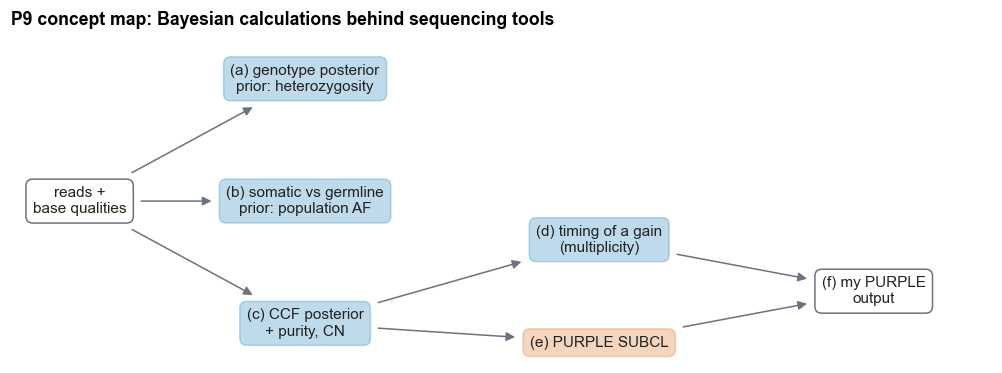

In [3]:
concept_map(
    {"reads": (0.07, 0.5, "reads +\nbase qualities", "white"),
     "a": (0.3, 0.88, "(a) genotype posterior\nprior: heterozygosity", COL["posterior"]),
     "b": (0.3, 0.5, "(b) somatic vs germline\nprior: population AF", COL["posterior"]),
     "c": (0.3, 0.12, "(c) CCF posterior\n+ purity, CN", COL["posterior"]),
     "d": (0.6, 0.38, "(d) timing of a gain\n(multiplicity)", COL["posterior"]),
     "e": (0.6, 0.06, "(e) PURPLE SUBCL", COL["alt"]),
     "f": (0.88, 0.22, "(f) my PURPLE\noutput", "white")},
    [("reads", "a", ""), ("reads", "b", ""), ("reads", "c", ""),
     ("c", "d", ""), ("c", "e", ""), ("e", "f", ""), ("d", "f", "")],
    title="P9 concept map: Bayesian calculations behind sequencing tools", size=(11.5, 3.8))

**그림에서 볼 것**: 왼쪽의 read 와 품질 점수에서 출발합니다. 사전을 무엇으로 두느냐(집단 heterozygosity, 집단 allele 빈도)에 따라 (a) genotype 호출, (b) 체세포 판정이 됩니다. purity 와 CN 을 더하면 (c) CCF 가 되고, CCF 와 multiplicity 에서 (d) 시점과 (e) PURPLE 의 subclonal 판정이 나옵니다.

## 먼저 알아 둘 것: 기호 사전

논문과 도구마다 같은 글자를 다른 뜻으로 씁니다(Mutect2 문서의 f, m 과 CCF 식의 f, m). 이 노트북은 아래처럼 나눠 씁니다.

| 기호 | 뜻 | 나오는 절 |
|---|---|---|
| $g$ | genotype (0/0, 0/1, 1/1) | (a) |
| $\epsilon$ | 염기 하나가 틀렸을 확률(Phred 점수에서) | (a), (b) |
| $f_{\text{pop}}$ | 집단 allele 빈도(gnomAD 등). Mutect2 문서의 $f$ | (b) |
| $\mu$ | 그 구간의 minor allele 비율. Mutect2 문서의 $m$ | (b) |
| $\pi$ | 자리 하나에 체세포 변이가 있을 사전확률 | (b) |
| $\ell_n$, $\ell_t$, $\ell^S_t$ | 정상 우도, 종양 우도, 종양의 체세포 우도 | (b) |
| $\rho$ | purity | (c)–(f) |
| $C$, $N$ | 종양 CN, 정상 CN | (c)–(f) |
| $m$ | multiplicity: 변이가 실린 copy 수 | (c)–(f) |
| $f$ | CCF: 암세포 중 그 변이를 가진 비율 | (c), (f) |
| $T$, $q$ | 증폭 시점, 변이 하나가 m = 2 일 확률 | (d) |
| VCN, $w$ | 변이 copy 수, subclone 비율 | (e), (f) |

## (a) genotype 호출: 사전이 실제로 무엇을 바꾸나

**한 줄 정의**: 각 자리에서 P5 의 genotype 우도(Li 2011 식 (2) [1])에 사전 P(0/0) = 0.9985, P(0/1) = 0.001, P(1/1) = 0.0005 를 곱해 사후를 구하고, 사후가 가장 큰 genotype 으로 호출합니다.

**왜 필요한가**: P6 에서는 한 자리만 봤습니다. 실제로는 수백만 자리를 한꺼번에 호출하므로, 우도만 쓰는 호출(MLE)과 사후 호출의 차이가 **오류 개수**로 드러납니다. 그리고 사후 확률이 "정직한가"(0.9 라고 한 자리의 90% 가 정말 변이인가, calibration)를 확인할 수 있습니다.

**가짜 데이터**: 100 만 자리, genotype 은 위 사전 비율대로, 깊이는 평균 8 인 포아송(저깊이 시퀀싱), read 의 60% 는 Q30, 40% 는 Q10. 사전은 P6 과 같이 GATK 주석의 $1-\sum \text{het}/i$ 를 항별로 읽은 장난감입니다. heterozygosity 0.001 은 한 사람이 이형접합일 확률이 아니라 "집단에서 고른 염색체 둘이 1,000 bp 에 한 번 다르다"는 집단유전학의 값이고(주석은 0.01 을 "differ … at a rate of 1 in 100 bp"로 설명), het/1 과 het/2 가 변이 allele 1 개·2 개의 항입니다 [3]. 실제 GATK 는 이 사전을 자리의 다형성 확률에만 쓴다고 주석에 적습니다 [3].

true variant sites: 1522
errors: {'n': 1000000, 'mle': {'fp': 15712, 'fn': 40}, 'post': {'fp': 39, 'fn': 235}}
calibration (mean reported P, share truly variant, n): [(0.172, 0.195, 297), (0.404, 0.427, 96), (0.59, 0.479, 48), (0.827, 0.839, 62), (0.962, 0.965, 114), (1.0, 0.999, 1104)]


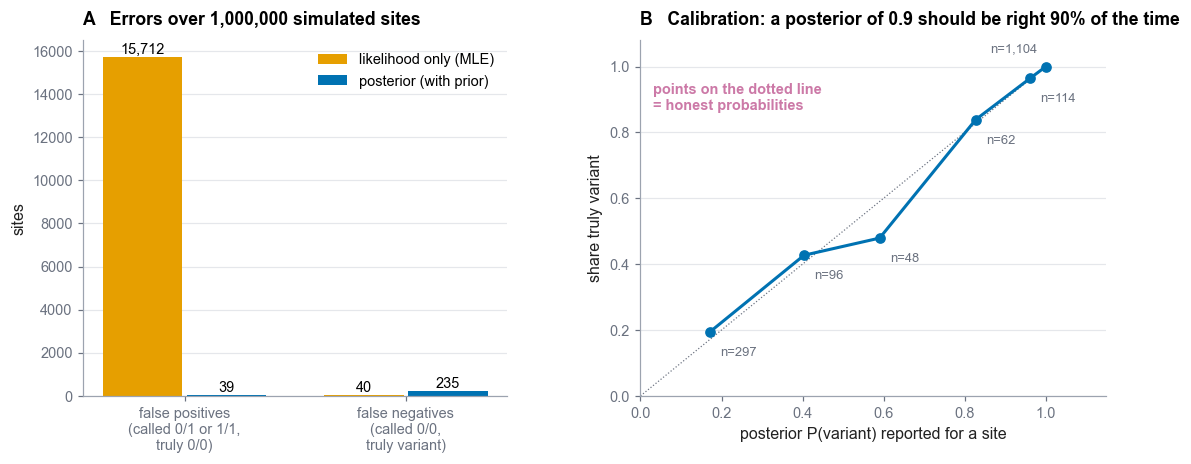

In [4]:
rng = np.random.default_rng(0)
N = 1_000_000
g_true = rng.choice(3, N, p=PRIOR_G)
dp = rng.poisson(8, N); n10 = rng.binomial(dp, 0.4); n30 = dp - n10
a30 = rng.binomial(n30, p_alt_read(g_true, 1e-3)); a10 = rng.binomial(n10, p_alt_read(g_true, 0.1))
ll = geno_loglik_counts(n30, a30, n10, a10)
post = softmax_rows(ll + np.log(PRIOR_G))
call_mle = ll.argmax(1); call_post = post.argmax(1)
conf = {"n": N}
for name, call in [("mle", call_mle), ("post", call_post)]:
    conf[name] = {"fp": int(np.sum((call > 0) & (g_true == 0))), "fn": int(np.sum((call == 0) & (g_true > 0)))}
p_var = post[:, 1] + post[:, 2]
edges = np.array([0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 1.0001])
idx = np.digitize(p_var, edges) - 1; ok = idx >= 0
calib = {"mid": [], "frac": [], "n": []}
for b in range(len(edges) - 1):
    sel = ok & (idx == b)
    if sel.sum() >= 20:
        calib["mid"].append(p_var[sel].mean()); calib["frac"].append(np.mean(g_true[sel] > 0)); calib["n"].append(int(sel.sum()))
print("true variant sites:", int(np.sum(g_true > 0)))
print("errors:", conf)
print("calibration (mean reported P, share truly variant, n):",
      [(round(m, 3), round(f_, 3), n) for m, f_, n in zip(calib["mid"], calib["frac"], calib["n"])])
draw_calling(conf, calib)
assert conf["mle"]["fp"] > 3 * conf["post"]["fp"]                    # 사전이 거짓 양성을 크게 줄임
assert len(calib["mid"]) >= 5 and all(abs(m - f_) < 0.12 for m, f_, n in zip(calib["mid"], calib["frac"], calib["n"]) if n > 40)

**그림에서 볼 것**
- A: 주황(우도만)은 거짓 양성이 만 개 넘게 나옵니다. 깊이 8 에서 Q10 오류 read 한두 개만 있어도 0/1 의 우도가 0/0 을 이기는 자리가 100 만 자리 중 많기 때문입니다. 파랑(사전 포함)은 거짓 양성이 수십 개로 줄고, 그 대가로 거짓 음성이 늘어납니다(위 출력의 숫자). 드문 것을 찾을 때 사전이 하는 일이 이것입니다(P6 의 기저율).
- B: 사후 P(변이)를 0.1–0.3, 0.3–0.5, … 구간으로 묶고, 그 구간에서 실제로 변이였던 비율을 찍었습니다. 점이 점선(대각선) 근처에 있으면 사후 확률이 정직하다는 뜻입니다. 이 가짜 데이터에서는 사전이 데이터를 만든 비율과 같아서 잘 맞습니다. 사전이 틀리면 이 그림이 대각선에서 벗어납니다(연습 문제 1).

> **실제 도구와 다른 점**: 실제 호출기는 염기 하나가 아니라 read 와 haplotype 을 맞춘 우도를 쓰고, 여러 시료를 함께 봅니다. 여기서는 Li 2011 의 두 염기 모형(틀린 염기는 늘 다른 쪽 allele 로 읽힘)과 품질 두 종류만 썼습니다. 틀린 염기가 나머지 세 염기로 고르게 간다고(ε/3) 보면 오류가 변이처럼 보이기 세 배 어려워집니다. P5·P6 의 Q10, 10 개 중 3 개 예에서 0/1 : 0/0 우도비가 2.0 에서 27.7 로 바뀌었으므로, 위 오류 개수도 이 가정에 따라 달라집니다.

## (b) 체세포냐 생식세포냐: Mutect2 germline 필터의 세 가설

**한 줄 정의**: 종양에서 변이가 보일 때, 가능성은 세 가지입니다 — 정상 세포에도 있는 생식세포 이형접합, 생식세포 동형접합, 종양에만 있는 체세포 변이. Mutect2 기술 문서는 이 세 가지의 비정규 확률을 다음과 같이 둡니다 [4]:

| 가능성 | 비정규 확률(문서) | 뜻 |
|---|---|---|
| germline het | $f_{\text{pop}}(1-f_{\text{pop}})\,\ell_n\,(1-\pi)\,[\ell_t(\mu) + \ell_t(1-\mu)]$ | 집단 빈도에서 이형접합일 사전 × 정상 우도 × 종양에서 minor·major allele 쪽일 우도 |
| germline hom alt | $f_{\text{pop}}^2\,\ell_n\,\ell_t(1)\,(1-\pi)$ | 동형접합 사전 × 정상 우도 × 종양 우도(AF ≈ 1) |
| somatic | $(1-f_{\text{pop}})^2\,\ell^S_t\,\pi$ | 정상에는 없을 사전 × 체세포 우도 × 체세포 사전 π |

(문서는 집단 빈도를 $f$, minor allele 비율을 $m$ 으로 쓰지만, 이 노트북은 (c) 의 CCF $f$, multiplicity $m$ 과 헷갈리지 않게 $f_{\text{pop}}$, $\mu$ 로 바꿔 씁니다.)

문서는 모든 우도를 "그 allele 이 없을 때의 우도를 1 로 둔 비"로 쓰고, 짝 정상 시료가 없으면 $\ell_n = 1$ 이라고 적습니다 [4].

**이 노트북의 장난감**: 우도를 이항으로 둡니다. 종양의 체세포 우도 $\ell^S_t$ 는 AF 를 0~1 평평한 사전으로 적분한 값($1/(d+1)$, P7 의 사후 예측과 같은 계산)입니다. μ 는 그 구간의 minor allele 비율로 0.5(균형)로 둡니다.

**기본값은 Mutect2 소스에서** (GATK 4.7.0.0 [13])
- 체세포 사전 π = $10^{-6}$: 필터 단계의 `DEFAULT_LOG_SNV_PRIOR = MathUtils.log10ToLog(-6)` (자연로그로 $\ln 10^{-6}$). 설명은 "Initial ln prior probability that a site has a somatic SNV"입니다.
- gnomAD 같은 germline resource 에 **없는** allele 의 $f_{\text{pop}}$: 설명 "Population allele fraction assigned to alleles not found in germline resource". 기본값은 짝 정상 시료가 없을 때(tumour-only) $5\times10^{-8}$ (`DEFAULT_AF_FOR_TUMOR_ONLY_CALLING`), 있을 때 $10^{-6}$ (`DEFAULT_AF_FOR_TUMOR_NORMAL_CALLING`).

**실제 도구와 다른 점**: 문서는 정상 시료의 het·hom 우도를 합친 하나의 $\ell_n$ 을 쓰고, 종양 우도는 allele 비율 군집 모형으로 보정한 값을 씁니다 [4]. 여기서는 정상의 het·hom 우도를 따로 두고 단순 이항을 씁니다.

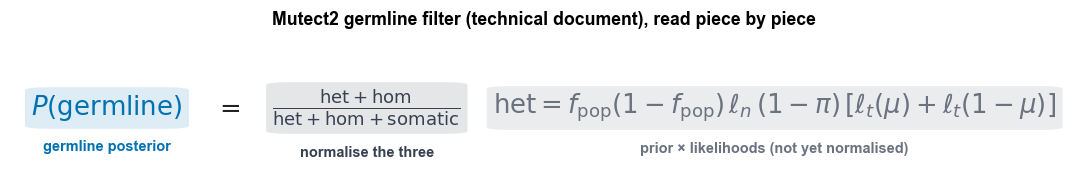

common SNP, normal has it | f_pop = 0.3, tumour 15/40, normal 9/20 -> {'het': 1.0, 'hom': 0.0, 'somatic': 0.0}
rare, normal clean | f_pop = 1e-5, tumour 12/40, normal 0/30 -> {'het': 0.0, 'hom': 0.0, 'somatic': 1.0}
no normal, VAF 0.45 | f_pop = 0.01 (seen in gnomAD) -> {'het': 1.0, 'hom': 0.0, 'somatic': 0.0}
no normal, VAF 0.45, not in gnomAD | f_pop = 5e-8 (Mutect2 tumour-only default) -> {'het': 0.2972, 'hom': 0.0, 'somatic': 0.7028}


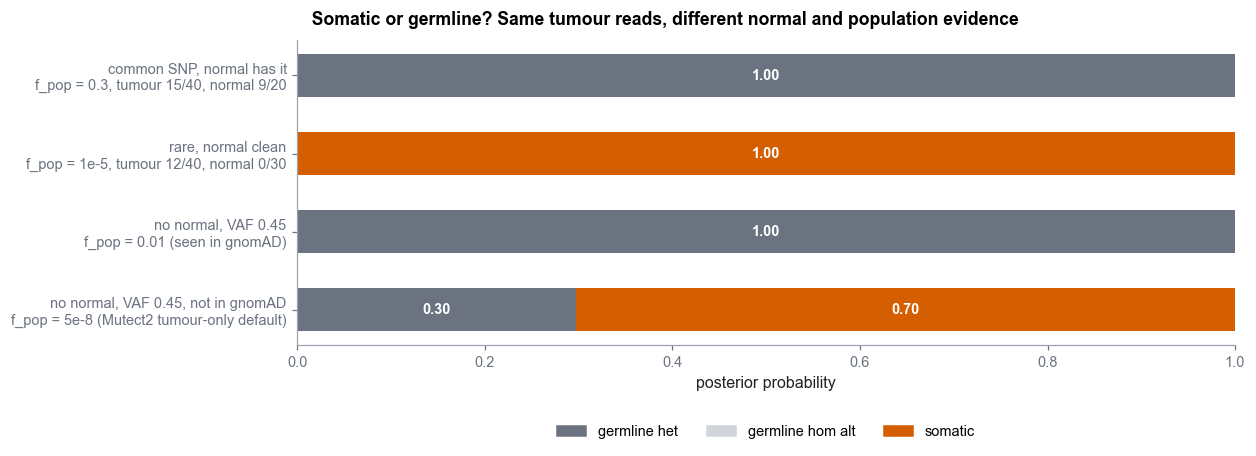

VAF 18/40: het likelihood (both allele terms) / somatic likelihood = 8.46
f_pop = 1e-6 (same as pi): [0.894 0.    0.106]
f_pop = 1e-8 (hypothetical): [0.078 0.    0.922]


In [5]:
show_formula([
    (r"$P(\mathrm{germline})$", COL["posterior"], "germline posterior"),
    (r"$=$", None, None),
    (r"$\frac{\mathrm{het} + \mathrm{hom}}{\mathrm{het} + \mathrm{hom} + \mathrm{somatic}}$", COL["evidence"], "normalise the three"),
    (r"$\mathrm{het} = f_{\mathrm{pop}}(1-f_{\mathrm{pop}})\,\ell_n\,(1-\pi)\,[\ell_t(\mu)+\ell_t(1-\mu)]$", COL["muted"],
     "prior × likelihoods (not yet normalised)"),
], title="Mutect2 germline filter (technical document), read piece by piece", height=1.7, width=12.5)
scen_in = [("common SNP, normal has it\nf_pop = 0.3, tumour 15/40, normal 9/20", dict(a_t=15, d_t=40, a_n=9, d_n=20, f_pop=0.3)),
           ("rare, normal clean\nf_pop = 1e-5, tumour 12/40, normal 0/30", dict(a_t=12, d_t=40, a_n=0, d_n=30, f_pop=1e-5)),
           ("no normal, VAF 0.45\nf_pop = 0.01 (seen in gnomAD)", dict(a_t=18, d_t=40, a_n=0, d_n=0, f_pop=0.01, normal=False)),
           ("no normal, VAF 0.45, not in gnomAD\nf_pop = 5e-8 (Mutect2 tumour-only default)", dict(a_t=18, d_t=40, a_n=0, d_n=0, f_pop=5e-8, normal=False))]
scen = [(lab, to_prob(germline_filter(**kw))) for lab, kw in scen_in]
for lab, pr in scen:
    print(lab.replace("\n", " | "), "->", dict(zip(["het", "hom", "somatic"], np.round(pr, 4))))
draw_germline(scen)
assert scen[0][1][0] > 0.99 and scen[1][1][2] > 0.99
assert scen[2][1][0] > 0.5 and abs(scen[3][1][2] - 0.70) < 0.01   # 정상 시료가 없으면 집단 빈도(사전)가 결론을 크게 좌우
lik_x = np.exp(np.logaddexp(log_binom(18, 40, 0.5), log_binom(18, 40, 0.5)) + np.log(41))   # 이형접합 우도(두 항) / 체세포 우도 1/(d+1)
print(f"VAF 18/40: het likelihood (both allele terms) / somatic likelihood = {lik_x:.2f}")
mid = to_prob(germline_filter(18, 40, 0, 0, 1e-6, normal=False)); print("f_pop = 1e-6 (same as pi):", np.round(mid, 3))
low = to_prob(germline_filter(18, 40, 0, 0, 1e-8, normal=False)); print("f_pop = 1e-8 (hypothetical):", np.round(low, 3))
assert abs(lik_x - 8.46) < 0.01 and mid[0] > 0.8 and low[2] > 0.9

**그림에서 볼 것**
- 막대 색: 진회색 = germline 이형접합, 옅은 회색 = germline 동형접합, 빨강 = 체세포.
- 첫 줄: gnomAD 에 흔한 변이($f_{\text{pop}}$ = 0.3)이고 정상 시료에도 반쯤 보이면, 거의 확실히 생식세포 이형접합입니다.
- 둘째 줄: 드문 변이이고 정상 시료 30 개 read 에 하나도 없으면 체세포입니다.
- 셋째·넷째 줄: 정상 시료가 없고 종양 VAF 가 0.45 로 같아도, 집단 빈도가 0.01 이면 germline 쪽입니다. gnomAD 에 없는 allele 에 Mutect2 가 tumour-only 일 때 주는 기본값 $f_{\text{pop}} = 5\times10^{-8}$ 이면 P(somatic) 은 약 0.70 입니다. **종양만 있을 때는 사전(집단 빈도와 체세포 사전 π 의 비)이 결론을 크게 좌우합니다.**
- 왜 0.70 에 그치나: VAF 0.45 는 이형접합의 0.5 에 잘 맞아서, 이형접합 우도(두 allele 항의 합)가 "AF 가 무엇이든 좋다"는 체세포 우도(1/(d+1))보다 약 8.5 배 큽니다(위 출력). germline 이형접합 대 체세포의 비는 대략 $(f_{\text{pop}}/\pi)\times 8.5$ 라, $f_{\text{pop}} = 5\times10^{-8}$ 이면 $0.05 \times 8.5 \approx 0.42$ → P(somatic) ≈ 0.70 입니다. $f_{\text{pop}}$ 를 π 와 같은 $10^{-6}$ 으로 두면 germline 약 0.89, 가정으로 $10^{-8}$ 까지 낮추면 P(somatic) 약 0.92 입니다(위 출력).

종양만 있을 때를 좀 더 넓게 봅니다. 종양 VAF 와 집단 빈도를 바꿔 가며 P(somatic) 을 칠했습니다.

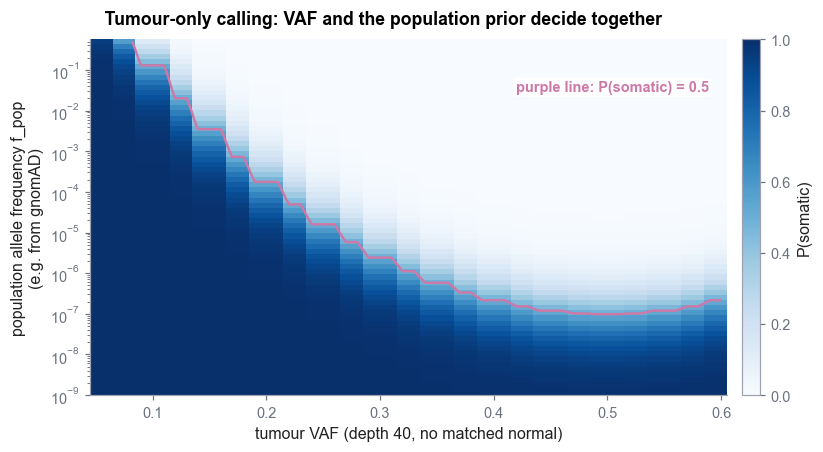

2/40: P(somatic) at f_pop 0.5 / 0.3 / 0.1 = 0.95 / 0.98 / 0.99;  lowest over f_pop 0.945
4/40: P(somatic) at f_pop 0.5 / 0.3 / 0.1 = 0.13 / 0.26 / 0.57;  lowest over f_pop 0.127
4/40 with f_pop 0.3: prior ratio het/somatic 4.3e+05, likelihood ratio het/somatic 6.8e-06 (= 1/1.5e+05)


In [6]:
vaf_g = np.linspace(0.05, 0.6, 56); af_g = np.logspace(-9, -0.3, 70); depth_to = 40
V, A = np.meshgrid(vaf_g, af_g)
p_som = np.zeros_like(V)
for i in range(V.shape[0]):
    for j in range(V.shape[1]):
        a_t = int(round(V[i, j] * depth_to))
        p_som[i, j] = to_prob(germline_filter(a_t, depth_to, 0, 0, A[i, j], normal=False))[2]
draw_tumour_only(vaf_g, af_g, p_som, depth_to)
f_many = np.logspace(-9, -0.3, 200)
for a_t in (2, 4):
    ps = [to_prob(germline_filter(a_t, depth_to, 0, 0, f_, normal=False))[2] for f_ in (0.5, 0.3, 0.1)]
    pmin = min(to_prob(germline_filter(a_t, depth_to, 0, 0, f_, normal=False))[2] for f_ in f_many)
    print(f"{a_t}/{depth_to}: P(somatic) at f_pop 0.5 / 0.3 / 0.1 = " + " / ".join(f"{p:.2f}" for p in ps) + f";  lowest over f_pop {pmin:.3f}")
prior_x = 0.3 / (0.7 * 1e-6)                                     # f(1-f) / ((1-f)^2 π)
lik_4 = np.exp(np.logaddexp(log_binom(4, 40, 0.5), log_binom(4, 40, 0.5)) + np.log(41))
print(f"4/40 with f_pop 0.3: prior ratio het/somatic {prior_x:.1e}, likelihood ratio het/somatic {lik_4:.1e} (= 1/{1 / lik_4:.1e})")
assert min(to_prob(germline_filter(2, 40, 0, 0, f_, normal=False))[2] for f_ in f_many) > 0.9
assert to_prob(germline_filter(4, 40, 0, 0, 0.3, normal=False))[2] < 0.5

**그림에서 볼 것**: 진한 파랑이 체세포 쪽, 자주색 선이 P(somatic) = 0.5 경계입니다.
- $f_{\text{pop}}$ 와 상관없이 체세포 쪽인 것은 VAF 가 아주 낮은 맨 왼쪽(40 개 중 2 개 = 0.05)뿐입니다. 가장 흔한 쪽($f_{\text{pop}}$ = 0.5)에서도 P(somatic) 이 0.9 를 넘습니다(위 출력).
- VAF 0.1(40 개 중 4 개)만 되어도 흔한 SNP 는 germline 이형접합이 이깁니다. P(somatic) 은 $f_{\text{pop}}$ = 0.5, 0.3, 0.1 에서 약 0.13, 0.26, 0.57 입니다(위 출력). 이형접합이라면 VAF 가 0.5 근처여야 하므로 4/40 은 이항 우도에서 약 $1.5\times10^5$ 배의 벌점을 받지만, $f_{\text{pop}} = 0.3$ 이면 사전 비 $f_{\text{pop}}(1-f_{\text{pop}})/[(1-f_{\text{pop}})^2\pi] \approx 4\times10^5$ 가 그 벌점보다 크기 때문입니다.
- VAF 가 0.5 근처인 오른쪽은 경계가 $f_{\text{pop}} \approx 10^{-7}$ 근처까지 내려갑니다. 집단에서 한 번이라도 보인 변이라면 germline 쪽으로 기웁니다. **종양만 있을 때, VAF 0.5 근처 변이의 판정은 거의 사전(집단 빈도)이 정합니다.**
- 이 장난감은 구간의 minor allele 비율을 μ = 0.5 로 고정했습니다. 실제 종양에서는 LOH 나 증폭으로 μ 가 0.5 가 아니면 germline 변이의 VAF 도 달라지고, Mutect2 문서는 이 값을 그 구간의 값으로 둡니다 [4]. 그래서 실제 경계는 구간마다 달라집니다.

## (c) VAF 에서 CCF 로: purity·CN·multiplicity 를 넣은 사후

**먼저 알아 둘 것**
- **CCF**(cancer cell fraction): 암세포 가운데 그 변이를 가진 세포의 비율. 모든 암세포에 있으면 1(클론성), 일부에만 있으면 1 보다 작음(subclone).
- **multiplicity m**: 변이를 가진 세포에서 그 변이가 실린 염색체 copy 수. 증폭 구간에서는 1 또는 2 이상이 될 수 있습니다.

**식** (Dentro 2021 STAR Methods [6], Gerstung 2020 Methods [8]): 종양 CN 이 $C$, 정상 CN 이 $N$(상염색체 2), purity $\rho$ 일 때 기대 VAF 는
$$E[\text{VAF}] = \frac{m\,f\,\rho}{N(1-\rho) + C\rho}$$
이고 f 가 CCF 입니다. Gerstung 2020 은 f = 1 이면 클론성, f < 1 이면 subclonal 이라 부릅니다 [8].

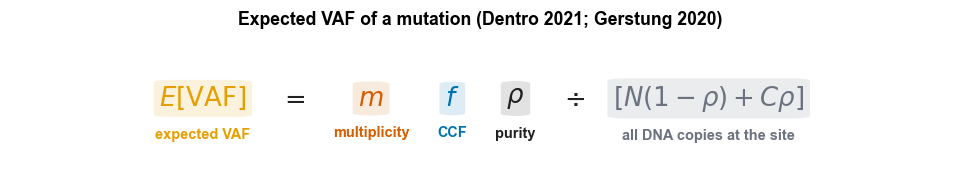

In [7]:
show_formula([
    (r"$E[\mathrm{VAF}]$", COL["likelihood"], "expected VAF"),
    (r"$=$", None, None),
    (r"$m$", COL["alt"], "multiplicity"),
    (r"$f$", COL["posterior"], "CCF"),
    (r"$\rho$", COL["ink"], "purity"),
    (r"$\div$", None, None),
    (r"$\left[N(1-\rho) + C\rho\right]$", COL["muted"], "all DNA copies at the site"),
], title="Expected VAF of a mutation (Dentro 2021; Gerstung 2020)")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $m$ | 멀티플리시티 | 변이가 실린 copy 수 | C 패널에서 m = 1 과 m = 2 가 다른 CCF 를 줌 |
| $f$ | CCF | 암세포 중 그 변이를 가진 비율 | 모든 패널의 가로축 |
| $\rho$ | 로(purity) | 시료 세포 중 암세포 비율 | — |
| $N(1-\rho) + C\rho$ | | 그 자리의 전체 DNA copy(정상 몫 + 종양 몫). PURPLE 노트북 B1 의 그것 | — |

**숫자로 따라가기**: purity 0.6, 이배체(C = 2), m = 1 이면 클론성 변이의 기대 VAF 는 $0.6/(2\times0.4 + 2\times0.6) = 0.30$ 입니다. 그래서 VAF 0.15 는 CCF 0.5 근처를 뜻합니다. 같은 VAF 0.17 이라도 CN 4(2+2) 구간이면 m = 1 일 때 기대 VAF 가 $0.6/(0.8 + 2.4) = 0.1875$ 라 CCF ≈ 0.9(클론성), m = 2 이면 0.375 라 CCF ≈ 0.45(subclone) 입니다.

사후는 CCF 를 0~1 에 평평한 사전으로 두고 격자(P8)에서 구합니다.

**판정 규칙을 고를 때의 함정**: CCF 는 1 을 넘을 수 없어서, 사후가 1 에서 잘립니다. 그래서 VAF 가 정확히 클론성 값(0.30)인 변이도 사후 넓이의 절반이 넘게(18/60 에서 0.58) 0.9 아래에 놓입니다(아래 출력). "P(CCF ≥ 0.9) ≥ 0.5 면 클론성" 같은 규칙을 쓰면 깊이가 낮을수록 클론성 변이를 subclone 으로 잘못 부릅니다. 이 노트북은 반대로 **"P(CCF < 0.9) ≥ 0.95 일 때만 subclonal, 아니면 클론성과 구별되지 않음"** 으로 부르겠습니다(이 노트북의 규칙). 기준 0.9 는 Dentro 2021 의 BayClone-C 설명에서 가져왔습니다. 이 방법은 마지막 단계에서 군집 평균이 0.9 를 넘는 CCF 군집을 모두 평균 1.0 인 클론성 군집 하나로 합칩니다 [6].

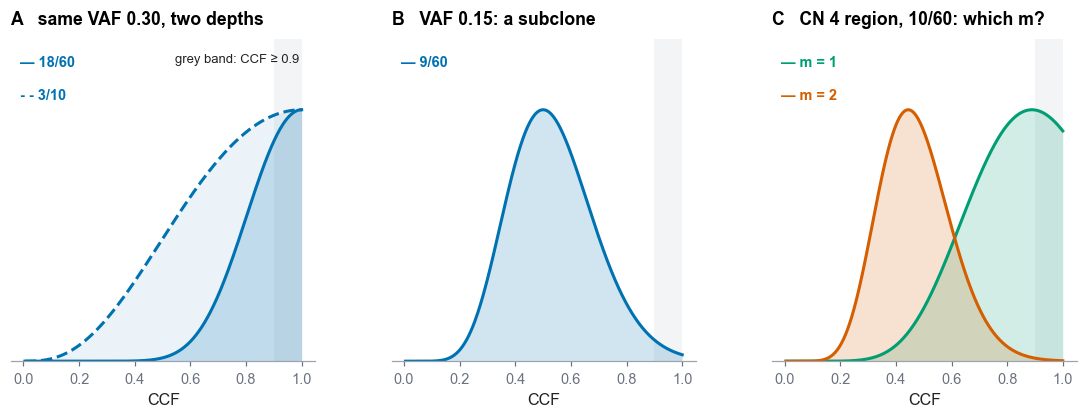

same VAF 0.30, two depths      18/60   mode 1.00  95% lower 0.61  P(CCF < 0.9) 0.58  -> not distinguishable from clonal
same VAF 0.30, two depths      3/10    mode 1.00  95% lower 0.28  P(CCF < 0.9) 0.79  -> not distinguishable from clonal
VAF 0.15: a subclone           9/60    mode 0.50  95% lower 0.27  P(CCF < 0.9) 0.99  -> subclonal
CN 4 region, 10/60: which m?   m = 1   mode 0.89  95% lower 0.46  P(CCF < 0.9) 0.75  -> not distinguishable from clonal
CN 4 region, 10/60: which m?   m = 2   mode 0.44  95% lower 0.25  P(CCF < 0.9) 1.00  -> subclonal


In [8]:
cases = [
    ("same VAF 0.30, two depths", [("18/60", ccf_post(18, 60, 0.6, 2, 1), COL["posterior"]),
                                    ("3/10", ccf_post(3, 10, 0.6, 2, 1), COL["posterior"], "--")]),
    ("VAF 0.15: a subclone", [("9/60", ccf_post(9, 60, 0.6, 2, 1), COL["posterior"])]),
    ("CN 4 region, 10/60: which m?", [("m = 1", ccf_post(10, 60, 0.6, 4, 1), COL["ok"]),
                                       ("m = 2", ccf_post(10, 60, 0.6, 4, 2), COL["alt"])])]
draw_ccf_cases(cases)
def p_below(post_c, cut=0.9):
    return post_c[CCF_GRID < cut].sum()

def lower95(post_c):
    return np.interp(0.025, np.cumsum(post_c), CCF_GRID)

for title, items in cases:
    for lab, post_c, *_ in items:
        call = "subclonal" if p_below(post_c) >= 0.95 else "not distinguishable from clonal"
        print(f"{title:30s} {lab:6s}  mode {CCF_GRID[np.argmax(post_c)]:.2f}  95% lower {lower95(post_c):.2f}  "
              f"P(CCF < 0.9) {p_below(post_c):.2f}  -> {call}")
(_, pA60, *_), (_, pA10, *_) = cases[0][1]
assert 0.4 < p_below(pA60) < 0.95 and lower95(pA60) > lower95(pA10) + 0.15      # 클론성인데도 넓이 절반쯤이 0.9 아래; 깊이 낮으면 더 넓음
assert abs(CCF_GRID[np.argmax(cases[1][1][0][1])] - 0.5) < 0.05 and p_below(cases[1][1][0][1]) >= 0.95
assert p_below(cases[2][1][0][1]) < 0.95 and p_below(cases[2][1][1][1]) >= 0.95

**그림에서 볼 것**
- A: VAF 는 둘 다 0.30(정확히 클론성 값)이고 둘 다 꼭대기가 CCF 1 입니다. 하지만 read 10 개(파선)는 사후가 훨씬 넓어 95% 구간 아래 끝이 낮습니다(위 출력). 둘 다 사후라 같은 파랑이고 선 모양으로 구분했습니다. 회색 띠가 CCF ≥ 0.9 인데, 클론성인 18/60(실선)도 넓이의 절반이 넘게(0.58) 띠 밖(0.9 아래)에 있습니다. 위에서 말한 "1 에서 잘린 사후"의 함정입니다.
- B: VAF 0.15 는 CCF 0.5 근처의 subclone 입니다.
- C: CN 4 구간에서 같은 10/60 이 m = 1(초록)이면 클론성과 구별되지 않고(꼭대기 0.89), m = 2(빨강)면 CCF 0.44 의 subclone 입니다. **multiplicity 를 어떻게 정하느냐가 CCF 를 좌우합니다.** 실제 도구들은 이 m 을 추정하는 방식이 서로 다릅니다(Gerstung 2020 은 방법들이 "각 allele 에 있는 변이 수를 계산하는 방식과 불확실성 처리가 조금씩 다르다"고 적습니다 [8]).

> **시퀀싱 데이터에서는**: PCAWG 의 PhylogicNDT 는 변이마다 purity 와 CN 을 반영한 CCF 확률 분포(ABSOLUTE)를 계산하고, 그 분포들을 Dirichlet Process 로 군집했다고 Dentro 2021 은 설명합니다 [6][7]. 위의 CCF 사후 하나하나가 그 군집의 재료입니다.

## (d) 증폭 시점: 두 copy 에 실린 변이가 시간을 알려 준다

**한 줄 정의**: 한 염색체 구간이 2+1 로 증폭되기 **전**에 증폭될 copy 에 생긴 변이는 함께 복사되어 m = 2 가 되고, 증폭 **뒤**에 생기거나 다른 copy 에 생긴 변이는 m = 1 입니다. 그래서 m = 2 변이의 비율이 증폭 시점을 알려 줍니다 [8].

**식** (Gerstung 2020 Methods "Timing of gains" [8]): $n_m$ 을 m 개 copy 에 실린 변이 수라 하면

| CN 상태 (major+minor) | 시점 T |
|---|---|
| 2+1 | $T = 3n_2/(2n_2+n_1)$ |
| 2+2 | $T = 2n_2/(2n_2+n_1)$ |
| 2+0 | $T = 2n_2/(2n_2+n_1)$ |

T 는 "그 구간의 클론성 변이가 쌓인 전체 시간 중 증폭이 일어난 자리"(molecular time) 입니다. 이 논문은 m > 1 이고 클론성인 변이를 early clonal, CN > 2 이고 minor CN 이 0 인 구간의 m = 1 클론성 변이를 late clonal 이라 부릅니다 [8].

**왜 2+1 에서 3n₂/(2n₂+n₁) 인가(이 노트북의 유도)**: 증폭 전(시간 T) 두 copy 에 변이가 같은 속도로 쌓이면, 증폭될 copy 에 $T$, 다른 copy 에 $T$ 만큼, 증폭 뒤에는 세 copy 에 $3(1-T)$ 만큼 쌓입니다. $n_2 \propto T$, $n_1 \propto T + 3(1-T) = 3 - 2T$ 이므로 $n_2/n_1 = T/(3-2T)$ 를 T 에 대해 풀면 $T = 3n_2/(2n_2 + n_1)$ 입니다.

**이 유도가 깔고 있는 조건**(이 노트북의 정리)
- 클론성 변이만 셉니다(subclone 변이는 모든 암세포에 있지 않아 m 을 이렇게 읽을 수 없음).
- 증폭은 한 번이고, 1+1 에서 2+1 이 되었습니다(2+0 의 식은 1+0 에서 한 copy 가 두 배가 된 경우).
- 증폭 뒤에 그 구간을 잃지 않았습니다(잃으면 m = 2 변이가 사라져 T 가 작게 나옴).
- copy 하나당 변이가 쌓이는 속도가 일정합니다. 그래서 T 는 실제 나이가 아니라 "쌓인 변이로 잰 시간"(molecular time)입니다.

**베이지안으로**: 변이 하나가 m = 2 일 확률을 $q = T/(3-T)$ 라 하면 $T = 3q/(1+q)$ 입니다. 각 변이의 read 가 m = 1, m = 2 중 어느 쪽에서 나왔는지 모르므로, $q$ 의 우도를 혼합 이항(P8)으로 쓰고 격자에서 사후를 구한 뒤 T 로 바꿉니다.

**사전에 숨은 가정**: q 를 0~0.5 에서 평평하게 두면 T 에서는 평평하지 않습니다. $q = T/(3-T)$ 이므로 T 의 사전 밀도는 $dq/dT = 3/(3-T)^2$ 에 비례하고, T = 0.05 에서 0.345, T = 0.95 에서 0.714 로 늦은 시점 쪽이 약 2 배 높습니다(아래 출력). 변이가 500 개면 우도가 이 차이를 압도하지만, 변이가 적은 구간에서는 이 사전이 결과를 늦은 쪽으로 끌 수 있습니다.

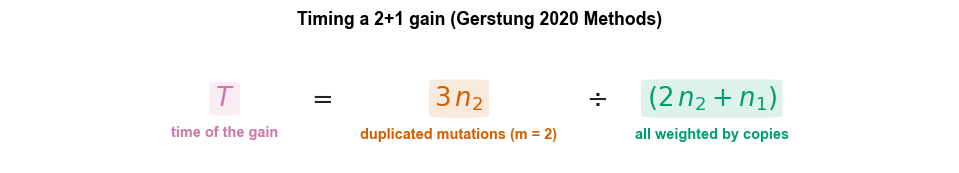

true T 0.4;  hard-count formula T 0.414;  posterior median 0.402, 95% [0.332, 0.477]


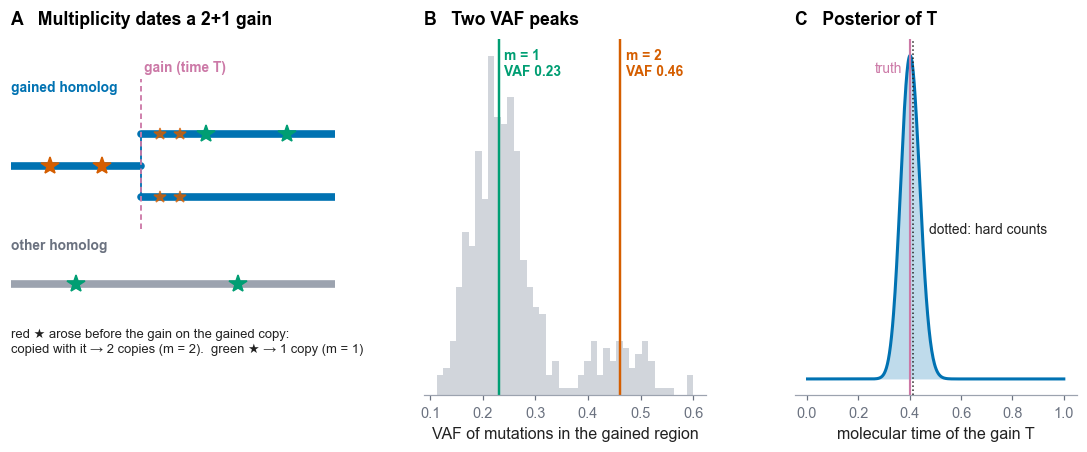

over 100 repeated simulations, the 95% interval contained the true T 94% of the time (MC error ±2.2%)
prior density of T implied by a flat q: 0.345 at T = 0.05, 0.714 at T = 0.95


In [9]:
show_formula([
    (r"$T$", COL["highlight"], "time of the gain"),
    (r"$=$", None, None),
    (r"$3\,n_2$", COL["alt"], "duplicated mutations (m = 2)"),
    (r"$\div$", None, None),
    (r"$(2\,n_2 + n_1)$", COL["ok"], "all weighted by copies"),
], title="Timing a 2+1 gain (Gerstung 2020 Methods)")
rng = np.random.default_rng(2)
T_true, rho, n_mut = 0.4, 0.6, 500
q_true = T_true / (3 - T_true)
m_true = np.where(rng.random(n_mut) < q_true, 2, 1)
den = 2 * (1 - rho) + 3 * rho
v1, v2 = rho / den, 2 * rho / den
dp_t = rng.poisson(80, n_mut); alt_t = rng.binomial(dp_t, np.where(m_true == 2, v2, v1))
qg = np.linspace(0.001, 0.4999, 600)                 # q ≤ 1/2 ⇔ T ≤ 1
l1 = log_binom(alt_t, dp_t, v1); l2 = log_binom(alt_t, dp_t, v2)
llq = np.array([np.sum(np.logaddexp(np.log1p(-q) + l1, np.log(q) + l2)) for q in qg])
post_q = np.exp(llq - llq.max()); post_q /= post_q.sum()
Tg = 3 * qg / (1 + qg)
post_T = post_q / np.gradient(Tg)                          # 변수 바꾸기(q → T)에 따른 밀도 보정
post_T /= np.sum((post_T[1:] + post_T[:-1]) / 2 * np.diff(Tg))      # 사다리꼴 적분으로 넓이 1
m_hard = np.where(l2 > l1, 2, 1)
T_hard = 3 * np.sum(m_hard == 2) / (2 * np.sum(m_hard == 2) + np.sum(m_hard == 1))
lo, hi = np.interp([0.025, 0.975], np.cumsum(post_q), Tg)
print(f"true T {T_true};  hard-count formula T {T_hard:.3f};  posterior median {np.interp(0.5, np.cumsum(post_q), Tg):.3f}, 95% [{lo:.3f}, {hi:.3f}]")
draw_timing(alt_t, dp_t, v1, v2, Tg, post_T, T_true, T_hard)
assert lo < T_true < hi
n2, n1 = np.sum(m_true == 2), np.sum(m_true == 1)
assert abs(3 * n2 / (2 * n2 + n1) - 3 * (n2 / n_mut) / (1 + n2 / n_mut)) < 1e-12   # 두 식이 같음

def timing_interval(seed):
    """같은 설정으로 데이터를 새로 만들어 T 의 95% 구간을 구한다(반복 확인용)"""
    r_ = np.random.default_rng(seed)
    m_ = np.where(r_.random(n_mut) < q_true, 2, 1)
    d_ = r_.poisson(80, n_mut); a_ = r_.binomial(d_, np.where(m_ == 2, v2, v1))
    l1_ = log_binom(a_, d_, v1); l2_ = log_binom(a_, d_, v2)
    ll_ = np.array([np.sum(np.logaddexp(np.log1p(-q) + l1_, np.log(q) + l2_)) for q in qg])
    p_ = np.exp(ll_ - ll_.max()); p_ /= p_.sum()
    return np.interp([0.025, 0.975], np.cumsum(p_), Tg)

cover = np.mean([lo_ < T_true < hi_ for lo_, hi_ in (timing_interval(100 + s_) for s_ in range(100))])
mc_se = np.sqrt(0.95 * 0.05 / 100)                                 # 100 번 반복한 비율의 몬테카를로 오차
print(f"over 100 repeated simulations, the 95% interval contained the true T {cover:.0%} of the time (MC error ±{mc_se:.1%})")
dens_T = lambda t: 3 / (3 - t) ** 2                                  # 평평한 q 사전이 T 에 주는 밀도(상수 배 무시)
print(f"prior density of T implied by a flat q: {dens_T(0.05):.3f} at T = 0.05, {dens_T(0.95):.3f} at T = 0.95")
assert abs(dens_T(0.05) - 0.345) < 1e-3 and abs(dens_T(0.95) - 0.714) < 1e-3
assert 0.88 <= cover <= 1.0

**그림에서 볼 것**
- A: 증폭(자주색 점선, 시간 T) 전에 증폭될 copy 에 생긴 변이(빨간 별)는 두 copy 에 실리고, 그 밖의 변이(초록 별)는 한 copy 에 실립니다.
- B: 증폭 구간 변이 500 개의 VAF 가 두 봉우리(m = 1: 0.23, m = 2: 0.46)로 나뉩니다. 빨간 봉우리가 작을수록 증폭이 일찍 일어났습니다.
- C: T 의 사후(파랑)가 진짜 값 0.4(자주색 선)를 포함합니다. 시뮬레이션 한 번의 결과는 뽑힌 변이 수에 따라 흔들리므로, 위 셀에서 100 번 다시 만들어 95% 구간이 진짜 T 를 포함한 비율도 확인했습니다(약 95% 여야 정직한 구간입니다. 100 번뿐이라 이 비율 자체가 ±2.2%p 쯤 흔들립니다). 점선은 변이마다 m 을 하나로 정해 센 값(hard counts)으로 계산한 T 입니다. 깊이 80 에서는 두 봉우리가 잘 갈려 둘이 비슷하지만, 깊이가 낮거나 purity 가 낮아 봉우리가 겹치면 하나로 정하는 방식은 불확실성을 숨깁니다.

> **실제 도구와 다른 점**: Gerstung 2020 은 세 방법이 "각 allele 에 있는 변이 수를 계산하는 방식과 불확실성 처리"에서 조금씩 다르다고 적고, 자세한 것은 보충 자료로 미룹니다 [8]. 이 노트북은 위 조건을 모두 참으로 놓고, CN 과 purity 를 정확히 안다고 가정했습니다. 또 이 논문이 T 를 실제 나이로 옮기는 단계에서는 위계적 베이지안 회귀를 Hamiltonian Monte Carlo 로 추정했다고 Extended Data 그림 설명에 적습니다 [8].

**직접 바꿔 보기**: `rho = 0.3` 이나 깊이 `30` 으로 바꾸면 두 봉우리가 겹치고 T 의 사후가 넓어집니다. 시점 분석에 깊이와 purity 를 묶은 기준(예: PURPLE 노트북 B1 의 NRPCC)을 두는 이유가 이것입니다(어떤 기준값이 적당한지는 이 노트북에서 확인하지 않았습니다).

## (e) PURPLE 의 subclonal likelihood(SUBCL) 를 직접 계산하기

**PURPLE 4.1 설명서가 말하는 것** [9]
1. 변이마다 copy 수를 구합니다: 관측 VAF 를 purity 로 보정하고 그 자리의 CN 을 곱해, 변이를 가진 염색체 수(variant copy number, VCN)를 구합니다.
2. 시료 전체 VCN 분포에서 봉우리(peak)를 차례로 찾습니다. 0.01 칸마다 ±0.1 안의 변이 밀도가 가장 높은 곳을 봉우리로 잡고, 봉우리 ±0.05 안의 변이들에 대해 **이항 분포**로 "다른 0.05 칸에 나타날 가능도"를 계산해 그 봉우리가 만드는 분포를 빼 나갑니다.
3. 봉우리 칸 변이의 40% 미만을 설명하는 봉우리는 버리고, 봉우리 VCN 이 **0.85 미만이면 subclonal** 로 표시합니다.
4. 변이마다 SUBCL = "그 VCN 칸에서 subclonal 봉우리로 맞춰진 변이의 비율".

**코드에서 확인한 것** [10]: `SubclonalLikelihood.java` 는 칸마다 `subclonal / (clonal + subclonal)` 을 계산하고, VCN 칸은 최대 2 까지만 둡니다(`MAX_PLOIDY = 2`, 그 위는 0).

**이 노트북의 장난감**: (P8 7 절과 같은) 이배체 종양, 클론성 70%·CCF 0.4 subclone 30%, 깊이 60. 봉우리 찾기는 건너뛰고 **알고 있는 두 봉우리**(VCN 1.0, 0.4)를 씁니다. VCN 은 $\text{VCN} = \text{VAF}\times[\rho C + 2(1-\rho)]/\rho$ 입니다. 이 식은 코드와 같습니다. `PurityAdjuster.purityAdjustedVAF` 가 정상 몫(정상 CN 2, 정상 세포에는 변이 없음)을 빼고 purity 로 나눠 $\text{VAF}\times[\rho C + 2(1-\rho)]/(\rho C)$ 를 만들고, `SomaticPurityEnrichment` 가 여기에 CN 을 곱해 $\text{VCN} = \max(0,\ \cdot \times C)$ 로 적습니다 [10]. 그리고 같은 변이들에 대해 P8 의 혼합 모형이 주는 사후 확률 "이 변이가 subclone 에서 왔을 확률"(책임, responsibility)과 비교합니다.

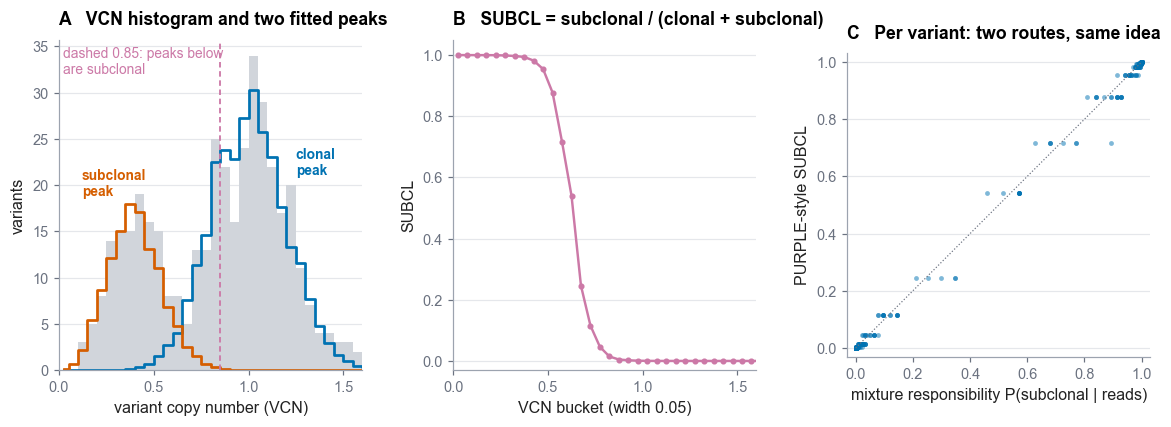

agreement of the two calls (> 0.5): 0.998;  correlation 0.999;  SUBCL call vs simulated truth: 0.980


In [10]:
rng = np.random.default_rng(6)
n_v, rho_e, cn_e = 400, 0.6, 2
sub = rng.random(n_v) < 0.3
dp_e = rng.poisson(60, n_v)
vaf_true = rho_e * np.where(sub, 0.4, 1.0) / 2
alt_e = rng.binomial(dp_e, vaf_true)
scale = (rho_e * cn_e + 2 * (1 - rho_e)) / rho_e
vcn = alt_e / dp_e * scale
width = 0.05; edges = np.arange(0, 2 + width, width); n_b = len(edges) - 1

def peak_histogram(peak_vcn, weight, depths):
    """설명서 2 번: 봉우리 근처 변이들의 깊이로, 이항 분포에 따라 다른 칸에 퍼지는 기대 개수"""
    h = np.zeros(n_b)
    for d in depths:
        k = np.arange(d + 1); pk = stats.binom.pmf(k, d, min(peak_vcn / scale, 1 - 1e-9))
        b = np.minimum((k / d * scale / width).astype(int), n_b - 1)
        h += np.bincount(b, weights=pk, minlength=n_b)
    return h / len(depths) * weight

near_c = dp_e[np.abs(vcn - 1.0) < 0.05]; near_s = dp_e[np.abs(vcn - 0.4) < 0.05]
hist_c = peak_histogram(1.0, np.sum(~sub), near_c); hist_s = peak_histogram(0.4, np.sum(sub), near_s)
tot = hist_c + hist_s
subcl_bucket = np.where(tot > 0, hist_s / np.where(tot > 0, tot, 1), 0.0)
vbin = np.minimum((vcn / width).astype(int), n_b - 1)
subcl_var = np.where(vcn < 2, subcl_bucket[vbin], 0.0)          # 코드: MAX_PLOIDY = 2 위는 0
lc = log_binom(alt_e, dp_e, rho_e / 2); ls = log_binom(alt_e, dp_e, rho_e * 0.4 / 2)
resp = 1 / (1 + np.exp(np.log(0.7) + lc - np.log(0.3) - ls))
draw_subcl(vcn, edges, hist_c, hist_s, subcl_bucket, resp, subcl_var)
agree = np.mean((subcl_var > 0.5) == (resp > 0.5)); r = np.corrcoef(resp, subcl_var)[0, 1]
acc_truth = np.mean((subcl_var > 0.5) == sub)
print(f"agreement of the two calls (> 0.5): {agree:.3f};  correlation {r:.3f};  SUBCL call vs simulated truth: {acc_truth:.3f}")
assert agree > 0.9 and r > 0.9 and acc_truth > 0.85

**그림에서 볼 것**
- A: 회색 막대가 변이 400 개의 VCN 분포입니다. 파란 계단선은 클론성 봉우리(VCN 1.0), 빨간 계단선은 subclone 봉우리(VCN 0.4)가 이항 퍼짐으로 만드는 기대 개수입니다. 자주색 점선 0.85 아래 봉우리가 subclonal 입니다.
- B: 칸마다 SUBCL = 빨강 / (빨강 + 파랑). VCN 0.45 아래는 거의 1, 0.8 위는 거의 0 이고, 그 사이(0.5–0.75)에서 넘어갑니다.
- C: 가로축은 P8 식 혼합 모형의 사후 책임 $\dfrac{w\,L_{\text{sub}}}{w\,L_{\text{sub}} + (1-w)\,L_{\text{clonal}}}$, 세로축은 PURPLE 식 SUBCL 입니다. 대부분 같은 쪽(둘 다 0 근처 또는 1 근처)에 놓입니다. 계산 길은 다르지만(봉우리 기대 개수의 비 vs 변이별 우도의 비) **"두 군집 중 어디에서 왔을 확률"이라는 같은 생각**입니다(위 출력: 일치율과 상관).

> **실제 도구와 다른 점**: PURPLE 은 봉우리를 데이터에서 차례로 찾고, 작은 봉우리를 걸러내고, 봉우리 합을 전체 변이 수에 맞춰 늘립니다 [9]. 여기서는 봉우리를 알고 있다고 놓았습니다. 또 코드(`PeakModelFactory.ploidyLikelihood`)는 봉우리 근처 변이마다 **그 변이 자신의 AF 와 깊이**로 이항 분포를 만들고(`new BinomialDistribution(TotalReadCount, alleleFrequency())`), 칸 경계를 "봉우리 VCN ÷ 그 변이의 VCN" 비율로 옮긴 변이 read 수로 계산한 뒤 0.01 단위로 반올림합니다 [10]. 이 노트북은 봉우리 VCN 에 해당하는 VAF 하나로 이항을 만들었습니다. 실제 VCN 은 구간마다 CN 이 달라 multiplicity 와 CCF 가 섞인 값입니다.

## (f) (선택) 내 PURPLE 결과에서: CCF 사후와 SUBCL 비교

환경 변수 `PURPLE_SAMPLE_DIR` 에 PURPLE 출력 폴더(`*.purple.purity.tsv`, `*.purple.somatic.vcf.gz` 가 있는 곳)를 넣으면 이 절이 돕니다. 설명서의 VCF 필드 `PURPLE_CN`(변이 주변 CN), `PURPLE_MACN`(minor allele CN), `PURPLE_VCN`(변이 copy 수), `SUBCL`(subclonal likelihood, 0 이 아닐 때만 적힘)을 씁니다 [9].

계산(이 노트북의 방법): PASS SNV 마다 multiplicity $m = \text{clip}(\text{round}(\text{VCN}), 1, \text{major CN})$ 로 두고(major CN = CN − MACN), (c) 의 CCF 사후로 P(CCF < 0.9) 를 구해 SUBCL 과 나란히 봅니다(일치율은 P(CCF < 0.9) ≥ 0.95 와 SUBCL > 0.5 를 비교). 출력에는 시료 이름·자리 정보를 찍지 않습니다.

In [11]:
import gzip, glob
PURPLE_DIR = os.environ.get("PURPLE_SAMPLE_DIR")
if not PURPLE_DIR:
    print("PURPLE_SAMPLE_DIR is not set: skipping the real-data section.")
else:
    pur_file = glob.glob(os.path.join(PURPLE_DIR, "*.purple.purity.tsv"))[0]
    pur = pd.read_csv(pur_file, sep="\t")
    purity_r, ploidy_r = float(pur["purity"].iloc[0]), float(pur["ploidy"].iloc[0])
    vcf = glob.glob(os.path.join(PURPLE_DIR, "*.purple.somatic.vcf.gz"))[0]
    rows = []
    with gzip.open(vcf, "rt") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS" or len(c[3]) != 1 or len(c[4]) != 1:
                continue
            info = dict(kv.split("=", 1) if "=" in kv else (kv, "1") for kv in c[7].split(";"))
            fmt = c[8].split(":")
            samples = [dict(zip(fmt, s.split(":"))) for s in c[9:]]
            ads = [list(map(int, s["AD"].split(","))) for s in samples]
            rows.append(dict(ad=ads, cn=float(info.get("PURPLE_CN", "nan")), macn=float(info.get("PURPLE_MACN", "nan")),
                             vcn=float(info.get("PURPLE_VCN", "nan")), subcl=float(info.get("SUBCL", "0"))))
    # 종양 열 찾기: 변이 read 비율이 더 높은 시료 열(정상 열은 대부분 0)
    alt_frac = np.array([[ad[1] / max(1, sum(ad)) for ad in r["ad"]] for r in rows]).mean(0)
    t_col = int(np.argmax(alt_frac))
    df = pd.DataFrame([dict(alt=r["ad"][t_col][1], dp=sum(r["ad"][t_col]), cn=r["cn"], macn=r["macn"],
                            vcn=r["vcn"], subcl=r["subcl"]) for r in rows]).dropna()
    df = df[(df.dp >= 10) & (df.cn > 0.5)]
    major = np.maximum(1, np.round(df.cn - df.macn))
    df["m"] = np.clip(np.round(df.vcn), 1, major)
    p_sub = []
    for a_, d_, cn_, m_ in zip(df.alt, df.dp, df.cn, df.m):
        pc = ccf_post(a_, d_, purity_r, cn_, m_)
        p_sub.append(pc[CCF_GRID < 0.9].sum())
    df["p_sub"] = p_sub
    print(f"purity {purity_r:.2f}, ploidy {ploidy_r:.2f}; PASS SNVs used: {len(df):,}; tumour column index {t_col}")
    agree_r = np.mean((df.p_sub >= 0.95) == (df.subcl > 0.5))
    print(f"share called subclonal: CCF posterior (P >= 0.95) {np.mean(df.p_sub >= 0.95):.3f}, PURPLE SUBCL > 0.5 {np.mean(df.subcl > 0.5):.3f}; agreement {agree_r:.3f}")
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"wspace": 0.3})
    axs[0].hist(df.vcn.clip(0, 3), bins=60, color=COL["none"]); axs[0].axvline(0.85, color=COL["highlight"], lw=1.2, ls=(0, (3, 2)))
    axs[0].set_xlabel("PURPLE_VCN (clipped at 3)"); axs[0].set_ylabel("PASS SNVs"); ygrid(axs[0])
    panel(axs[0], "A", "Variant copy number in my sample")
    hb = axs[1].hexbin(df.p_sub, df.subcl, gridsize=25, cmap="Blues", bins="log", mincnt=1)
    axs[1].plot([0, 1], [0, 1], color=COL["muted"], lw=0.8, ls=":")
    axs[1].set_xlabel("this notebook: P(CCF < 0.9 | reads)"); axs[1].set_ylabel("PURPLE SUBCL"); axs[1].set_aspect("equal")
    fig.colorbar(hb, ax=axs[1], pad=0.02).set_label("SNVs (log)")
    panel(axs[1], "B", f"Two subclonal calls per SNV (agreement {agree_r:.2f})")
    plt.show()

PURPLE_SAMPLE_DIR is not set: skipping the real-data section.


**이 절을 읽는 법**(실제 데이터로 돌렸을 때)
- A 에서 VCN 1 근처 봉우리가 클론성 변이, 0.85 아래 봉우리가 있으면 subclone 후보입니다. 증폭 구간의 m = 2 변이는 VCN 2 근처에 따로 봉우리를 만듭니다.
- B 의 두 값은 대각선에 놓이지 않는 것이 보통입니다. PURPLE 의 SUBCL 은 "그 VCN 칸에서 subclonal 봉우리의 몫"이라, 클론성 봉우리 근처 변이는 0 에 가깝게 나옵니다. 이 노트북의 P(CCF < 0.9) 는 (c) 에서 본 "1 에서 잘린 사후" 때문에 클론성 변이도 0.3–0.8 쯤에 퍼집니다. 한 시료로 돌려 본 결과도 이런 모양이었습니다(그 사본은 git 에 올리지 않는 data/ 에만 있음). 그래서 연속값끼리가 아니라 판정 규칙(P(CCF < 0.9) ≥ 0.95, SUBCL > 0.5)을 거친 뒤 일치율로 비교합니다.
- 두 판정이 어긋나는 변이는 multiplicity 를 어떻게 정했는지(여기서는 VCN 반올림), 깊이가 낮은지, CN 이 흔들리는 구간인지에 따라 생길 수 있습니다. purity 가 낮은 시료일수록 사후가 넓어 어긋남이 늘 것으로 예상합니다(이 노트북에서 시험하지 않은 예상).

## 연습 문제

1. (a) 에서 사전 P(0/1) 을 0.01 로 10 배 키우면(데이터는 그대로) 거짓 양성과 calibration 이 어떻게 바뀔까요?
2. (b) 의 셋째 줄(정상 시료 없음, $f_{\text{pop}}$ = 0.01)에 정상 시료 20 read 가 생겼고 모두 참조 염기라면 결론이 어떻게 될까요?
3. purity 0.5, CN 3, m = 1, VAF 0.10 이면 CCF 는 대략 얼마입니까?
4. 2+1 구간에서 m = 2 변이가 40 개, m = 1 변이가 160 개면 T 는?

<details><summary>정답 보기</summary>

1. 사후가 변이 쪽으로 기울어 거짓 양성이 늘고, 실제 비율(0.001)보다 큰 사후를 말하게 되어 calibration 점이 대각선 아래로 내려갑니다(사후가 너무 자신 있게 변이라고 말함).
2. 정상 시료에 없다는 강한 증거가 생겨 germline 가설의 우도가 크게 떨어지고 somatic 이 됩니다(아래 셀).
3. 기대 VAF(CCF = 1) $= 0.5/(2\times0.5 + 3\times0.5) = 0.2$ → CCF ≈ 0.10/0.2 = 0.5.
4. $T = 3\times40/(2\times40 + 160) = 120/240 = 0.5$.

</details>

In [12]:
pr2 = to_prob(germline_filter(18, 40, 0, 20, 0.01, normal=True))
print("2:", dict(zip(["het", "hom", "somatic"], np.round(pr2, 4))), "  3:", 0.10 / (0.5 / (2 * 0.5 + 3 * 0.5)), "  4:", 3 * 40 / (2 * 40 + 160))
assert pr2[2] > 0.5 and abs(3 * 40 / (2 * 40 + 160) - 0.5) < 1e-12

2: {'het': 0.0767, 'hom': 0.0, 'somatic': 0.9233}   3: 0.5   4: 0.5


## 정리

- genotype 호출은 "Li 2011 의 read 우도 × 집단 사전"이고, 사전이 수백만 자리의 거짓 양성을 크게 줄입니다. 사전이 맞으면 사후 확률이 정직합니다(calibration).
- 체세포 판정은 세 가설(germline het, hom, somatic)의 베이즈 비교입니다. 짝 정상 시료가 없으면 집단 빈도 사전이 결론을 거의 정합니다(Mutect2 germline 필터).
- CCF 사후는 기대 VAF $m f\rho/[N(1-\rho)+C\rho]$ 와 이항 우도로 구합니다. 깊이가 낮으면 넓고, multiplicity 를 어떻게 정하느냐가 결과를 바꿉니다.
- 증폭 시점은 m = 2 변이의 비율로 정해지고($T = 3n_2/(2n_2+n_1)$, 2+1), 혼합 우도로 그 불확실성까지 구할 수 있습니다.
- PURPLE 의 SUBCL 은 VCN 칸마다 "subclonal 봉우리 몫 ÷ 전체 몫"이고, 혼합 모형의 사후 책임과 같은 생각입니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| [1] | Li H. 2011. A statistical framework for SNP calling, mutation discovery, association mapping and population genetical parameter estimation from sequencing data. *Bioinformatics* 27(21):2987–2993. [doi:10.1093/bioinformatics/btr509](https://doi.org/10.1093/bioinformatics/btr509), [PMC3198575](https://pmc.ncbi.nlm.nih.gov/articles/PMC3198575/) | (a) 식 (2), 두 염기 모형 |
| [2] | Cock PJA 외. 2010. *Nucleic Acids Res* 38(6):1767–1771. [doi:10.1093/nar/gkp1137](https://doi.org/10.1093/nar/gkp1137) | Phred 점수 → 오류 확률 |
| [3] | GATK 4.7.0.0 소스 [`HomoSapiensConstants.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/utils/variant/HomoSapiensConstants.java), [`GenotypeCalculationArgumentCollection.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/tools/walkers/genotyper/GenotypeCalculationArgumentCollection.java) | (a) heterozygosity 1e-3 과 그 뜻(100 bp 에 한 번), $1-\sum\text{het}/i$, 사전은 다형성 확률에만 쓰임 |
| [4] | GATK 개발팀. Mutect2 기술 문서 [`docs/mutect/mutect.tex`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/docs/mutect/mutect.tex) (4.7.0.0), Germline Filter 절 | (b) 세 가능성의 비정규 확률, 우도의 약속, 정상 없으면 $\ell_n=1$, $\ell_n$ 은 het+hom 합 |
| [5] | Benjamin D 외. 2019. Calling Somatic SNVs and Indels with Mutect2. *bioRxiv* [doi:10.1101/861054](https://doi.org/10.1101/861054) | Mutect2 가 여러 확률 모형으로 genotyping·filtering 한다는 초록 |
| [6] | Dentro SC 외. 2021. Characterizing genetic intra-tumor heterogeneity across 2,658 human cancer genomes. *Cell* 184(8):2239–2254.e39. [doi:10.1016/j.cell.2021.03.009](https://doi.org/10.1016/j.cell.2021.03.009), [PMC8054914](https://pmc.ncbi.nlm.nih.gov/articles/PMC8054914/) | (c) STAR Methods 의 VAF 식, BayClone-C 의 "cluster means greater than 0.9" 군집 합치기, PhylogicNDT 설명(ABSOLUTE CCF 분포, Dirichlet Process 군집) |
| [7] | Leshchiner I 외. 2018. Comprehensive analysis of tumour initiation, spatial and temporal progression under multiple lines of treatment. *bioRxiv* [doi:10.1101/508127](https://doi.org/10.1101/508127) | PhylogicNDT 원 논문(초록만 확인) |
| [8] | Gerstung M 외. 2020. The evolutionary history of 2,658 cancers. *Nature* 578:122–128. [doi:10.1038/s41586-019-1907-7](https://doi.org/10.1038/s41586-019-1907-7), [PMC7054212](https://pmc.ncbi.nlm.nih.gov/articles/PMC7054212/) | (c) E[X] 식, 클론성 정의, (d) "Timing of gains" 의 T 식 세 가지, early/late clonal 정의, 방법 간 차이(변이 수 계산·불확실성 처리), Extended Data 그림 설명의 Hamiltonian Monte Carlo |
| [9] | PURPLE README, purple-v4.1, [hmftools/purple@purple-v4.1](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md), "Clonality and Biallelic status", somatic VCF 필드 | (e) VCN, 봉우리 찾기, 0.85, 40%, SUBCL 정의, (f) 필드 이름 |
| [10] | hmftools purple-v4.1 [`SubclonalLikelihood.java`](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple/somatic/SubclonalLikelihood.java), [`PeakModelFactory.java`](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple/fittingsnv/PeakModelFactory.java), [`PurityAdjuster.java`](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple/fitting/PurityAdjuster.java), [`SomaticPurityEnrichment.java`](https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/src/main/java/com/hartwig/hmftools/purple/somatic/SomaticPurityEnrichment.java) | (e) subclonal/(clonal+subclonal), MAX_PLOIDY 2, 변이별 AF 의 이항 분포와 0.01 반올림(`ploidyLikelihood`), VCN 식(`purityAdjustedVAF`, `max(0, vaf * copyNumber)`) |
| [11] | Gelman A 외. *Bayesian Data Analysis*, 3rd ed. [책 누리집](https://sites.stat.columbia.edu/gelman/book/) | 같이 볼 교재 |
| [12] | McElreath R. *Statistical Rethinking* 2023, [GitHub 강의표](https://github.com/rmcelreath/stat_rethinking_2023) | 같이 볼 강의 |
| [13] | GATK 4.7.0.0 소스 [`M2ArgumentCollection.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/tools/walkers/mutect/M2ArgumentCollection.java), [`M2FiltersArgumentCollection.java`](https://github.com/broadinstitute/gatk/blob/4.7.0.0/src/main/java/org/broadinstitute/hellbender/tools/walkers/mutect/filtering/M2FiltersArgumentCollection.java) | (b) `DEFAULT_AF_FOR_TUMOR_ONLY_CALLING = 5e-8`, `DEFAULT_AF_FOR_TUMOR_NORMAL_CALLING = 1e-6`, `DEFAULT_LOG_SNV_PRIOR = log10ToLog(-6)` 과 그 설명 |

(a)–(e) 의 가짜 데이터, 장난감 사전·우도, 그림 속 숫자는 이 노트북에서 직접 만들고 계산한 결과입니다.